<a href="https://colab.research.google.com/github/akshaybhatt97/365-DAYS-AI-ML-WITH-AKSHAY/blob/main/day_073_umap.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 73/365 — UMAP
## Another powerful way to visualize high-dimensional data

Yesterday we explored **t-SNE**.

Today we cover another popular nonlinear dimensionality-reduction technique:

**UMAP — Uniform Manifold Approximation and Projection**

UMAP projects high-dimensional data into 2D or 3D and is widely used for visualization of embeddings, images, biological data, and other high-dimensional representations.


In [1]:
# Install once if needed:
# pip install umap-learn

import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import umap


## 1. Load the Digits dataset

Each image is:

`8 × 8 pixels = 64 features`


In [2]:
digits=load_digits()
X=digits.data
y=digits.target

print("Dataset shape:",X.shape)
print("Features:",X.shape[1])
print("Classes:",len(set(y)))


Dataset shape: (1797, 64)
Features: 64
Classes: 10


## 2. Scale the data


In [3]:
X_scaled=StandardScaler().fit_transform(X)


## 3. PCA baseline


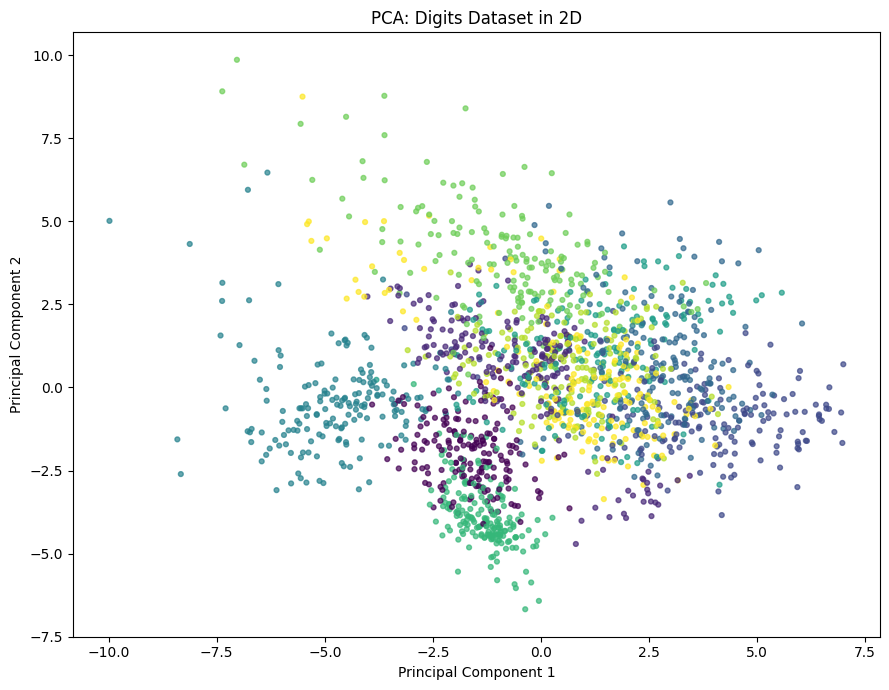

In [4]:
pca=PCA(n_components=2)
X_pca=pca.fit_transform(X_scaled)

plt.figure(figsize=(9,7))
plt.scatter(X_pca[:,0],X_pca[:,1],c=y,s=12,alpha=0.7)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA: Digits Dataset in 2D")
plt.tight_layout()
plt.show()


## 4. Apply UMAP

Two important parameters:

### `n_neighbors`
Controls how local or broad the neighborhood view is.

### `min_dist`
Controls how tightly points can pack together in the low-dimensional map.


In [5]:
reducer=umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    random_state=42
)

X_umap=reducer.fit_transform(X_scaled)

print("UMAP output shape:",X_umap.shape)


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP output shape: (1797, 2)


## 5. Visualize UMAP


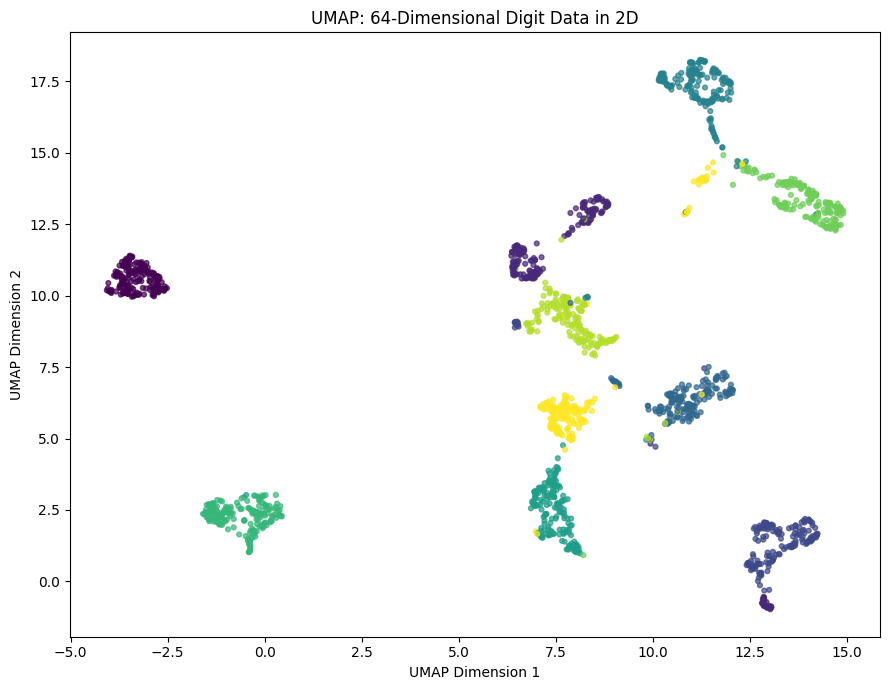

In [6]:
plt.figure(figsize=(9,7))
plt.scatter(X_umap[:,0],X_umap[:,1],c=y,s=12,alpha=0.7)
plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")
plt.title("UMAP: 64-Dimensional Digit Data in 2D")
plt.tight_layout()
plt.show()


## 6. PCA vs t-SNE vs UMAP

### PCA
- linear
- fast
- useful for compression and preprocessing

### t-SNE
- nonlinear
- focuses strongly on local neighborhoods
- mostly used for visualization

### UMAP
- nonlinear
- often faster than t-SNE on larger datasets
- preserves local structure well
- commonly used for embedding visualization

None is universally best.


## 7. How `n_neighbors` changes the map


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


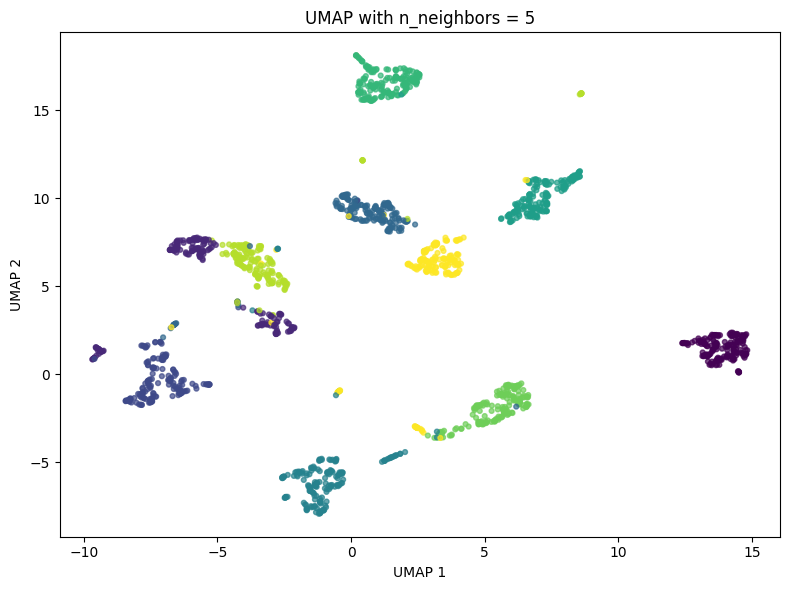

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


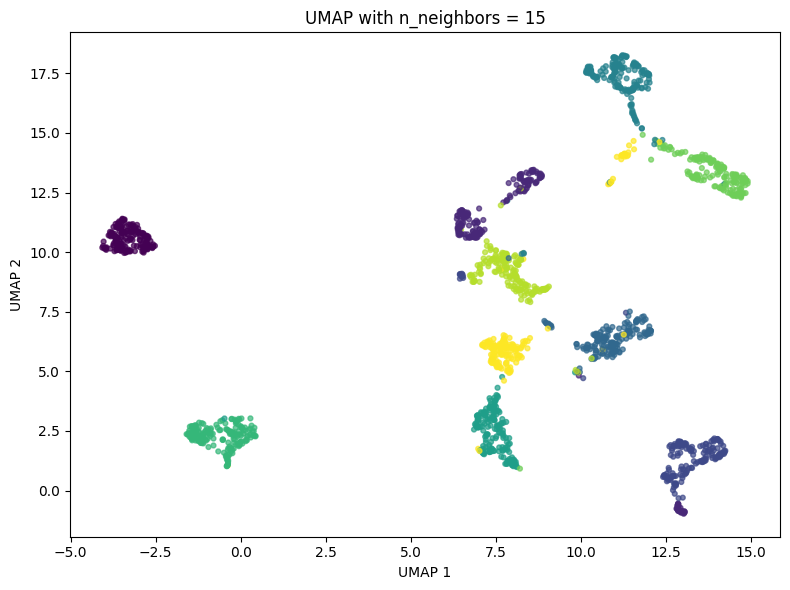

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


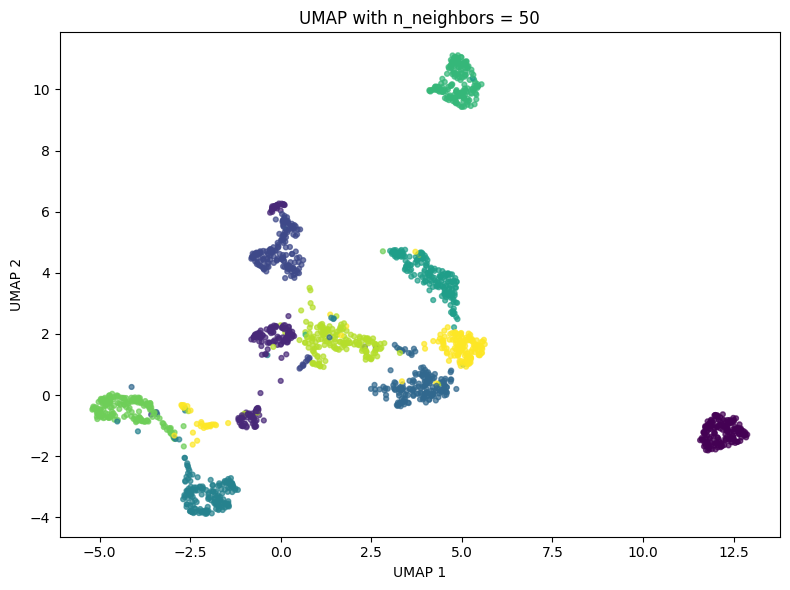

In [7]:
for n in [5,15,50]:
    reducer=umap.UMAP(
        n_components=2,
        n_neighbors=n,
        min_dist=0.1,
        random_state=42
    )

    embedding=reducer.fit_transform(X_scaled)

    plt.figure(figsize=(8,6))
    plt.scatter(
        embedding[:,0],
        embedding[:,1],
        c=y,
        s=12,
        alpha=0.7
    )
    plt.xlabel("UMAP 1")
    plt.ylabel("UMAP 2")
    plt.title(f"UMAP with n_neighbors = {n}")
    plt.tight_layout()
    plt.show()


## Enterprise intuition

Modern AI systems often produce vectors with hundreds or thousands of dimensions:

- document embeddings
- customer embeddings
- product embeddings
- image representations
- behavior vectors

UMAP can project these into 2D so humans can inspect clusters, outliers, and similarity patterns.


## Important caution

UMAP is a visualization / representation technique.

A visually separated cluster is not automatically a real business segment.

The result can change with:
- `n_neighbors`
- `min_dist`
- distance metric
- preprocessing
- random seed

Always validate what the picture seems to suggest.


## What does this teach?

- UMAP is nonlinear dimensionality reduction.
- It is widely used for visualizing high-dimensional data.
- `n_neighbors` controls neighborhood scale.
- `min_dist` affects cluster compactness in the map.
- It is especially useful for embeddings.
- It complements PCA and t-SNE.

> **PCA compresses variance. t-SNE emphasizes local neighbors. UMAP gives us another practical map of high-dimensional structure.**


## References

- https://umap-learn.readthedocs.io/en/latest/
- https://arxiv.org/abs/1802.03426
- https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html
